# Modeling and PID Control of a DC Motor Under Variable Load

**Engineering question:** How does feedback control improve DC-motor speed regulation when the motor experiences load disturbances and measurement noise?

**Project objective:** Build a physics-based DC motor model, compare open-loop/P control with PID feedback, introduce a controlled load disturbance and measurement noise, and quantify speed-tracking performance, control effort, and robustness.

**Tools:** Python, NumPy, Pandas, Matplotlib, SciPy (optional only where useful).  
**Environment:** Google Colab; no hardware required.

### Engineering workflow
**Model → Control → Disturb → Measure → Diagnose → Improve → Retest**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (10, 5)

SEED = 42
rng = np.random.default_rng(SEED)

# DC motor parameters (SI units)
R = 2.0          # armature resistance, ohm
L = 0.5          # armature inductance, H
Kt = 0.10        # torque constant, N*m/A
Ke = 0.10        # back-EMF constant, V/(rad/s)
J = 0.02         # rotor inertia, kg*m^2
b = 0.002        # viscous friction, N*m/(rad/s)

V_MAX = 12.0     # supply/controller voltage limit, V
DT = 0.001       # simulation step, s
SIM_TIME = 5.0   # simulation duration, s

TARGET_SPEED = 60.0   # rad/s
LOAD_START = 2.5      # s
LOAD_TORQUE = 0.03    # N*m

print("DC motor model initialized.")
print(f"Target speed: {TARGET_SPEED:.1f} rad/s")
print(f"Load disturbance: {LOAD_TORQUE:.3f} N*m starting at {LOAD_START:.1f} s")

DC motor model initialized.
Target speed: 60.0 rad/s
Load disturbance: 0.030 N*m starting at 2.5 s


In [ ]:
# State equations:
# di/dt = (V - R*i - Ke*omega) / L
# domega/dt = (Kt*i - b*omega - T_load) / J

def motor_step(state, voltage, load_torque, dt=DT):
    current, omega = state

    voltage = np.clip(voltage, -V_MAX, V_MAX)

    di_dt = (voltage - R * current - Ke * omega) / L
    domega_dt = (Kt * current - b * omega - load_torque) / J

    new_current = current + di_dt * dt
    new_omega = omega + domega_dt * dt

    return np.array([new_current, new_omega])

def load_profile(t):
    return LOAD_TORQUE if t >= LOAD_START else 0.0

def simulate_controller(controller, target_speed=TARGET_SPEED,
                        sim_time=SIM_TIME, noise_std=0.0, seed=SEED):
    t = np.arange(0, sim_time + DT, DT)
    current = 0.0
    omega = 0.0

    states = []
    voltages = []
    loads = []
    measured_speed = []

    local_rng = np.random.default_rng(seed)
    controller.reset()

    for time in t:
        load = load_profile(time)

        measurement = omega + local_rng.normal(0, noise_std) if noise_std > 0 else omega
        voltage = controller.update(target_speed, measurement, DT)
        voltage = np.clip(voltage, -V_MAX, V_MAX)

        states.append([current, omega])
        voltages.append(voltage)
        loads.append(load)
        measured_speed.append(measurement)

        current, omega = motor_step([current, omega], voltage, load)

    return {
        "time": t,
        "current": np.array(states)[:, 0],
        "speed": np.array(states)[:, 1],
        "voltage": np.array(voltages),
        "load": np.array(loads),
        "measured_speed": np.array(measured_speed),
    }

print("Motor dynamics and simulation engine ready.")

Motor dynamics and simulation engine ready.


In [ ]:
class OpenLoopController:
    def __init__(self, voltage=8.0):
        self.voltage = voltage

    def reset(self):
        pass

    def update(self, target, measurement, dt):
        return self.voltage


class PController:
    def __init__(self, kp=0.25):
        self.kp = kp

    def reset(self):
        pass

    def update(self, target, measurement, dt):
        error = target - measurement
        return self.kp * error


class PIDController:
    def __init__(self, kp=0.25, ki=3.0, kd=0.002,
                 output_limit=V_MAX, integral_limit=10.0):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.output_limit = output_limit
        self.integral_limit = integral_limit
        self.integral = 0.0
        self.previous_error = 0.0

    def reset(self):
        self.integral = 0.0
        self.previous_error = 0.0

    def update(self, target, measurement, dt):
        error = target - measurement

        derivative = (error - self.previous_error) / dt if dt > 0 else 0.0

        # Conditional integration helps prevent excessive windup.
        candidate_integral = np.clip(
            self.integral + error * dt,
            -self.integral_limit,
            self.integral_limit
        )

        unsaturated = (
            self.kp * error
            + self.ki * candidate_integral
            + self.kd * derivative
        )

        output = np.clip(unsaturated, -self.output_limit, self.output_limit)

        # Only accept the integral update when saturation is not
        # pushing the output farther in the same direction as the error.
        if not (
            (output >= self.output_limit and error > 0)
            or (output <= -self.output_limit and error < 0)
        ):
            self.integral = candidate_integral

        self.previous_error = error
        return output


# Quick controller sanity tests
for controller in [OpenLoopController(), PController(), PIDController()]:
    controller.reset()
    test_output = controller.update(TARGET_SPEED, 0.0, DT)
    print(type(controller).__name__, "initial output =", round(test_output, 3), "V")

OpenLoopController initial output = 8.0 V
PController initial output = 15.0 V
PIDController initial output = 12.0 V


## 1. Baseline experiment: open-loop, P control, and PID control

We first compare three control strategies under the same motor model and the same step target.  
A load torque is introduced halfway through the simulation to test disturbance rejection.

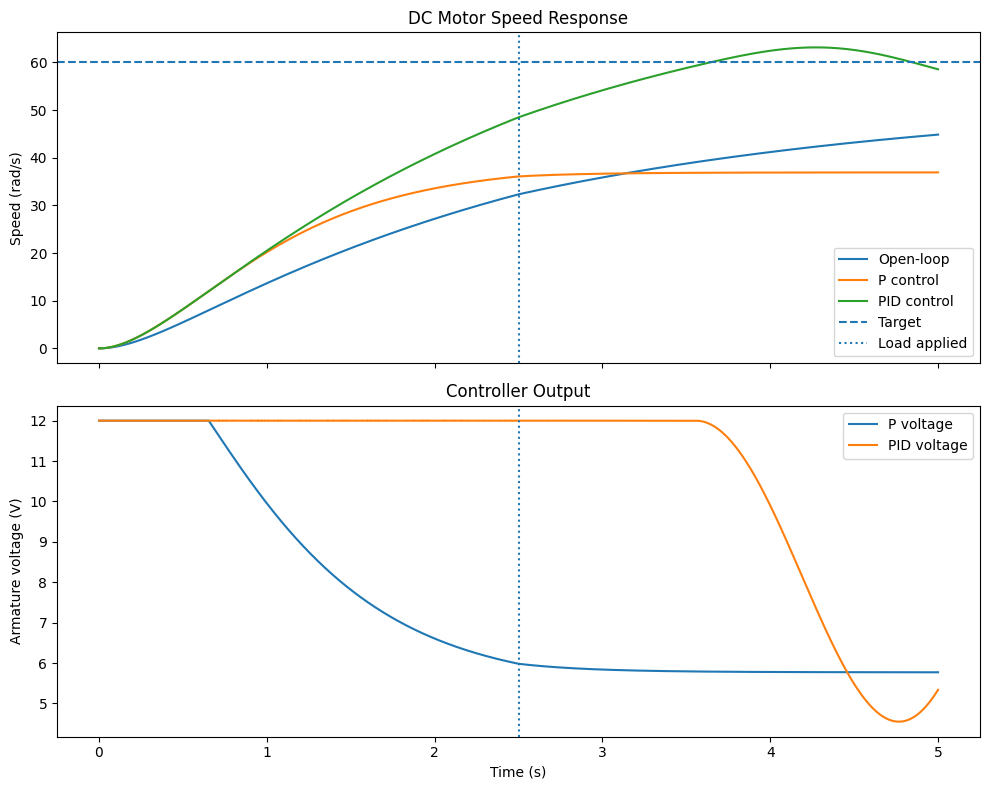

In [ ]:
open_loop = simulate_controller(OpenLoopController(voltage=8.0))
p_result = simulate_controller(PController(kp=0.25))
pid_result = simulate_controller(PIDController(kp=0.25, ki=3.0, kd=0.002))

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax[0].plot(open_loop["time"], open_loop["speed"], label="Open-loop")
ax[0].plot(p_result["time"], p_result["speed"], label="P control")
ax[0].plot(pid_result["time"], pid_result["speed"], label="PID control")
ax[0].axhline(TARGET_SPEED, linestyle="--", label="Target")
ax[0].axvline(LOAD_START, linestyle=":", label="Load applied")
ax[0].set_ylabel("Speed (rad/s)")
ax[0].set_title("DC Motor Speed Response")
ax[0].legend()

ax[1].plot(p_result["time"], p_result["voltage"], label="P voltage")
ax[1].plot(pid_result["time"], pid_result["voltage"], label="PID voltage")
ax[1].axvline(LOAD_START, linestyle=":")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Armature voltage (V)")
ax[1].set_title("Controller Output")
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
def calculate_metrics(result, target=TARGET_SPEED, load_start=LOAD_START):
    t = result["time"]
    w = result["speed"]
    e = target - w

    # Steady-state window: final 0.5 s
    ss_mask = t >= (t[-1] - 0.5)

    steady_state_error = np.mean(np.abs(e[ss_mask]))
    rmse = np.sqrt(np.mean(e**2))
    max_abs_error = np.max(np.abs(e))

    # Rise time: first time reaching 90% of target
    threshold = 0.90 * target
    reached = np.where(w >= threshold)[0]
    rise_time = t[reached[0]] if len(reached) else np.nan

    # Peak overshoot relative to target
    peak = np.max(w)
    overshoot_pct = max(0.0, (peak - target) / target * 100)

    # Integral absolute error and control effort
    iae = np.trapezoid(np.abs(e), t)
    control_effort = np.trapezoid(np.abs(result["voltage"]), t)

    # Average speed before and after disturbance
    pre_mask = (t >= 2.0) & (t < load_start)
    post_mask = t >= (t[-1] - 0.5)

    pre_load_speed = np.mean(w[pre_mask])
    post_load_speed = np.mean(w[post_mask])

    return {
        "Rise time (s)": rise_time,
        "Overshoot (%)": overshoot_pct,
        "RMSE (rad/s)": rmse,
        "Steady-state error (rad/s)": steady_state_error,
        "Max absolute error (rad/s)": max_abs_error,
        "IAE (rad/s*s)": iae,
        "Control effort (V*s)": control_effort,
        "Pre-load mean speed (rad/s)": pre_load_speed,
        "Post-load mean speed (rad/s)": post_load_speed,
    }

baseline_metrics = pd.DataFrame({
    "Open-loop": calculate_metrics(open_loop),
    "P control": calculate_metrics(p_result),
    "PID control": calculate_metrics(pid_result),
}).T

display(baseline_metrics.round(4))

,Rise time (s),Overshoot (%),RMSE (rad/s),Steady-state error (rad/s),Max absolute error (rad/s),IAE (rad/s*s),Control effort (V*s),Pre-load mean speed (rad/s),Post-load mean speed (rad/s)
Open-loop,NaN,0.0000,34.7445,15.9567,60.0,159.5347,40.0000,29.8245,44.0433
P control,NaN,0.0000,32.7525,23.0867,60.0,153.7422,37.2573,34.9636,36.9133
PID control,2.987,5.2403,27.2030,1.2225,60.0,96.2958,53.9027,44.7363,60.7817


## 2. Disturbance-response analysis

The key EEE/control question is not only whether the motor reaches the target, but how well the feedback controller rejects a change in load torque.

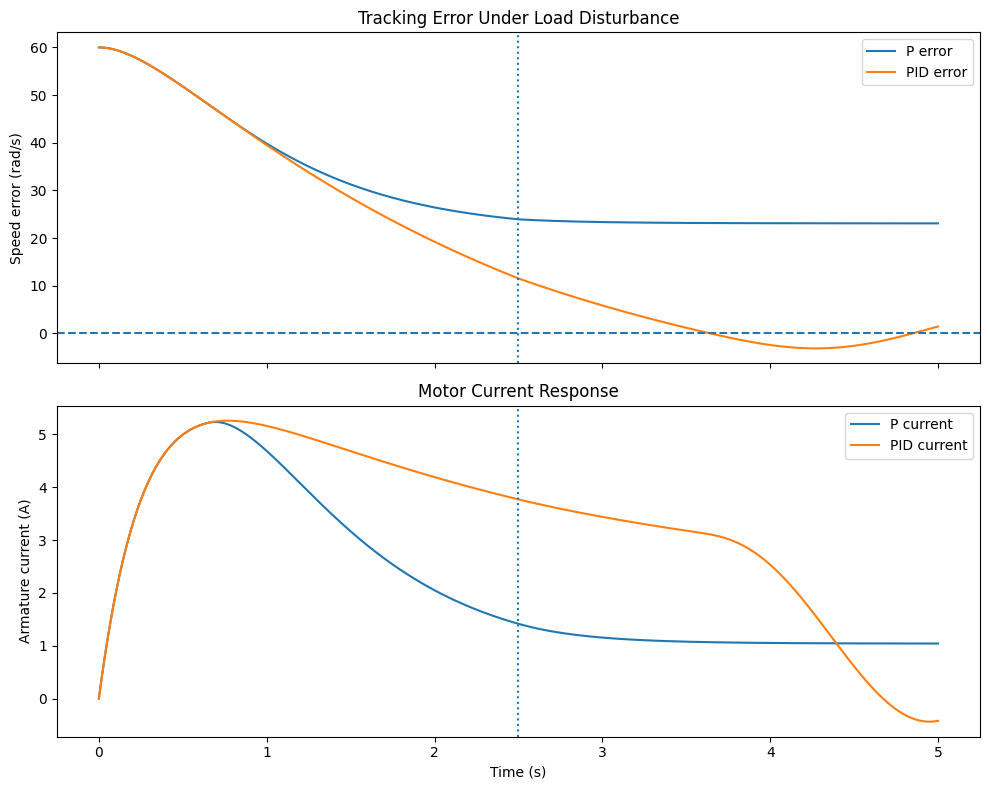

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax[0].plot(p_result["time"], TARGET_SPEED - p_result["speed"], label="P error")
ax[0].plot(pid_result["time"], TARGET_SPEED - pid_result["speed"], label="PID error")
ax[0].axhline(0, linestyle="--")
ax[0].axvline(LOAD_START, linestyle=":")
ax[0].set_ylabel("Speed error (rad/s)")
ax[0].set_title("Tracking Error Under Load Disturbance")
ax[0].legend()

ax[1].plot(p_result["time"], p_result["current"], label="P current")
ax[1].plot(pid_result["time"], pid_result["current"], label="PID current")
ax[1].axvline(LOAD_START, linestyle=":")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Armature current (A)")
ax[1].set_title("Motor Current Response")
ax[1].legend()

plt.tight_layout()
plt.show()

,Maximum load-induced deviation (rad/s),Maximum deviation during first 1 s (rad/s),Final 1-s mean deviation (rad/s)
P control,1.4863,1.0857,1.4199
PID control,1.9637,1.3188,1.0108


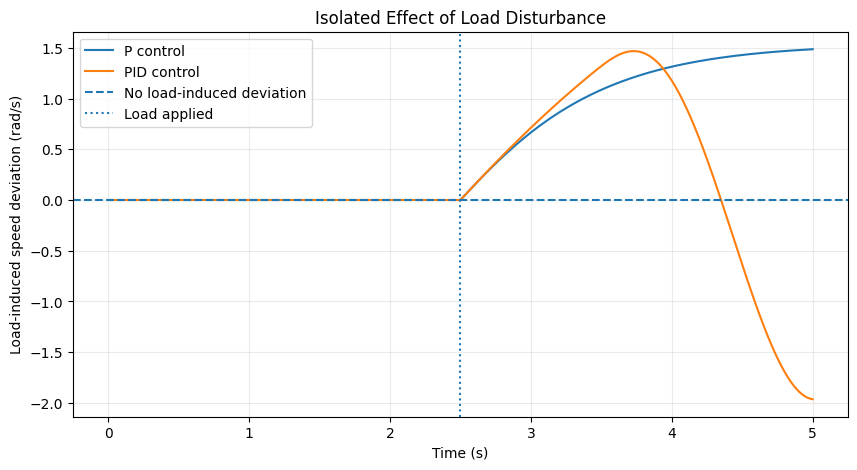

In [ ]:
# ============================================================
# UNIFIED MOTOR SIMULATION & DISTURBANCE ANALYSIS
# ============================================================

def simulate_motor(controller, load_profile=0.0, noise_std=0.0, seed=None):
    """
    Unified simulation function supporting constant loads,
    time-varying load profiles, measurement noise, and correct current tracking.
    """
    if seed is not None:
        np.random.seed(seed)

    t = np.arange(0, SIM_TIME + DT, DT)
    current = 0.0
    omega = 0.0
    controller.reset()

    states = []
    voltages = []
    loads = []

    for time in t:
        # Evaluate load whether it's a constant value or a lambda function
        load = load_profile(time) if callable(load_profile) else load_profile

        # Add optional measurement noise
        measurement = omega + (np.random.normal(0, noise_std) if noise_std > 0 else 0.0)

        voltage = controller.update(TARGET_SPEED, measurement, DT)
        voltage = np.clip(voltage, -V_MAX, V_MAX)

        states.append([current, omega])
        voltages.append(voltage)
        loads.append(load)

        current, omega = motor_step([current, omega], voltage, load)

    states = np.array(states)

    return {
        "time": t,
        "current": states[:, 0],
        "speed": states[:, 1],
        "voltage": np.array(voltages),
        "load": np.array(loads)
    }


# ------------------------------------------------------------
# Run each controller twice:
# 1. No external load
# 2. External load of LOAD_TORQUE
# ------------------------------------------------------------

p_no_load = simulate_motor(PController(kp=0.25), load_profile=0.0)
p_loaded = simulate_motor(
    PController(kp=0.25),
    load_profile=lambda t: LOAD_TORQUE if t >= LOAD_START else 0.0
)

pid_no_load = simulate_motor(PIDController(kp=0.25, ki=3.0, kd=0.002), load_profile=0.0)
pid_loaded = simulate_motor(
    PIDController(kp=0.25, ki=3.0, kd=0.002),
    load_profile=lambda t: LOAD_TORQUE if t >= LOAD_START else 0.0
)


# ------------------------------------------------------------
# Calculate the effect of the load itself
# ------------------------------------------------------------

def calculate_disturbance_metrics(no_load_result, loaded_result):
    t = loaded_result["time"]
    no_load_speed = no_load_result["speed"]
    loaded_speed = loaded_result["speed"]

    speed_deviation = no_load_speed - loaded_speed
    post_load = t >= LOAD_START
    deviation_after_load = speed_deviation[post_load]

    max_deviation = np.max(np.abs(deviation_after_load))

    final_window = t >= (t[-1] - 1.0)
    final_deviation = np.mean(np.abs(speed_deviation[final_window]))

    first_window = (t >= LOAD_START) & (t < LOAD_START + 1.0)
    first_deviation = np.max(np.abs(speed_deviation[first_window]))

    return {
        "Maximum load-induced deviation (rad/s)": max_deviation,
        "Maximum deviation during first 1 s (rad/s)": first_deviation,
        "Final 1-s mean deviation (rad/s)": final_deviation
    }


p_disturbance = calculate_disturbance_metrics(p_no_load, p_loaded)
pid_disturbance = calculate_disturbance_metrics(pid_no_load, pid_loaded)

disturbance_comparison = pd.DataFrame({
    "P control": p_disturbance,
    "PID control": pid_disturbance
}).T

display(disturbance_comparison.round(4))


# ------------------------------------------------------------
# Plot: isolated effect of the load disturbance
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.plot(p_loaded["time"], p_no_load["speed"] - p_loaded["speed"], label="P control")
plt.plot(pid_loaded["time"], pid_no_load["speed"] - pid_loaded["speed"], label="PID control")
plt.axhline(0, linestyle="--", label="No load-induced deviation")
plt.axvline(LOAD_START, linestyle=":", label="Load applied")
plt.xlabel("Time (s)")
plt.ylabel("Load-induced speed deviation (rad/s)")
plt.title("Isolated Effect of Load Disturbance")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 3. Measurement-noise robustness

Real feedback systems do not measure speed perfectly.  
We therefore repeat the PID experiment with controlled Gaussian measurement noise.

The physical motor state remains noise-free; only the **controller's measured speed** is corrupted. This isolates the effect of imperfect feedback information.

In [ ]:
NOISE_LEVELS = [0.0, 0.5, 1.0, 2.0, 3.0]  # rad/s
N_TRIALS = 20

noise_records = []

for noise_std in NOISE_LEVELS:
    for trial in range(N_TRIALS):
        result = simulate_controller(
            PIDController(kp=0.25, ki=3.0, kd=0.002),
            noise_std=noise_std,
            seed=SEED + trial
        )
        metrics = calculate_metrics(result)

        noise_records.append({
            "Noise std (rad/s)": noise_std,
            "Trial": trial + 1,
            **metrics
        })

noise_df = pd.DataFrame(noise_records)

noise_summary = (
    noise_df
    .groupby("Noise std (rad/s)")
    [["RMSE (rad/s)", "Steady-state error (rad/s)",
      "Max absolute error (rad/s)", "Control effort (V*s)"]]
    .agg(["mean", "std"])
)

display(noise_summary.round(4))

RMSE (rad/s)         Steady-state error (rad/s)          \
                          mean     std                       mean     std   
Noise std (rad/s)                                                           
0.0                    27.2030  0.0000                     1.2225  0.0000   
0.5                    27.2395  0.0017                     1.9489  0.0536   
1.0                    27.2990  0.0066                     3.1361  0.0903   
2.0                    27.4807  0.0271                     4.0066  0.1245   
3.0                    27.7435  0.0485                     3.8001  0.1806   

                  Max absolute error (rad/s)      Control effort (V*s)          
                                        mean  std                 mean     std  
Noise std (rad/s)                                                               
0.0                                     60.0  0.0              53.9027  0.0000  
0.5                                     60.0  0.0              54.3308  0.0279  
1.0                                     60.0  0.0              55.1890  0.0567  
2.0                                     60.0  0.0              56.5297  0.0729  
3.0                                     60.0  0.0              56.9011  0.1030

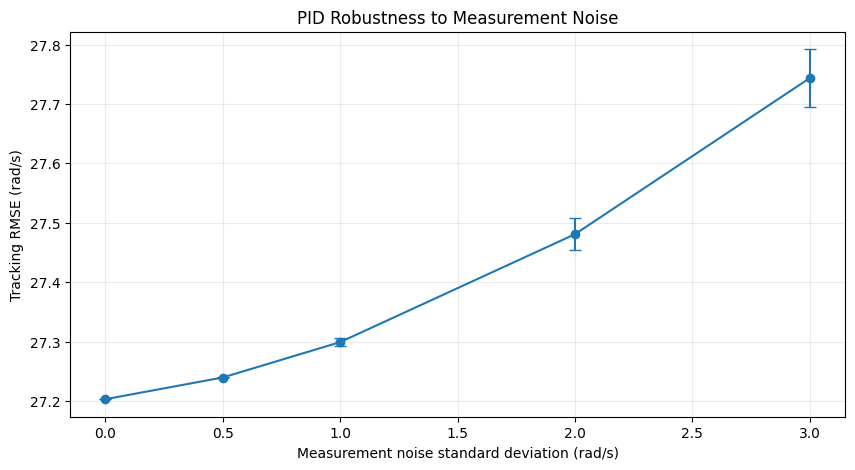

In [ ]:
# Plot mean ± standard deviation for RMSE as measurement noise increases.
noise_mean = noise_df.groupby("Noise std (rad/s)")["RMSE (rad/s)"].mean()
noise_std = noise_df.groupby("Noise std (rad/s)")["RMSE (rad/s)"].std()

plt.figure(figsize=(10, 5))
plt.errorbar(
    noise_mean.index,
    noise_mean.values,
    yerr=noise_std.values,
    marker="o",
    capsize=4
)
plt.xlabel("Measurement noise standard deviation (rad/s)")
plt.ylabel("Tracking RMSE (rad/s)")
plt.title("PID Robustness to Measurement Noise")
plt.grid(alpha=0.25)
plt.show()

## 4. Controller robustness to load magnitude

We now vary the external load rather than changing controller gains.  
This tests whether the feedback controller maintains speed regulation as the mechanical disturbance becomes stronger.

In [ ]:
LOAD_LEVELS = [0.00, 0.01, 0.02, 0.03, 0.04, 0.05]  # N*m
load_records = []

for load_value in LOAD_LEVELS:
    # Clean profile lambda mapping the current sweep value
    load_profile_fn = lambda t, lv=load_value: lv if t >= LOAD_START else 0.0

    for name, controller in [
        ("P", PController(kp=0.25)),
        ("PID", PIDController(kp=0.25, ki=3.0, kd=0.002))
    ]:
        # Utilizing the unified simulation function (tracks current correctly)
        result = simulate_motor(controller, load_profile=load_profile_fn)
        metrics = calculate_metrics(result)

        load_records.append({
            "Load torque (N*m)": load_value,
            "Controller": name,
            "Steady-state error (rad/s)": metrics["Steady-state error (rad/s)"],
            "RMSE (rad/s)": metrics["RMSE (rad/s)"],
            "Post-load mean speed (rad/s)": metrics["Post-load mean speed (rad/s)"]
        })

load_df = pd.DataFrame(load_records)
display(load_df.round(4))

,Load torque (N*m),Controller,Steady-state error (rad/s),RMSE (rad/s),Post-load mean speed (rad/s)
0,0.00,P,21.6254,32.3857,38.3746
1,0.00,PID,1.4712,27.1966,59.3103
2,0.01,P,22.1125,32.5062,37.8875
3,0.01,PID,1.2992,27.1973,59.8245
4,0.02,P,22.5996,32.6285,37.4004
5,0.02,PID,1.2134,27.1994,60.3188
6,0.03,P,23.0867,32.7525,36.9133
7,0.03,PID,1.2225,27.2030,60.7817
8,0.04,P,23.5738,32.8782,36.4262
9,0.04,PID,1.3328,27.2079,61.1969


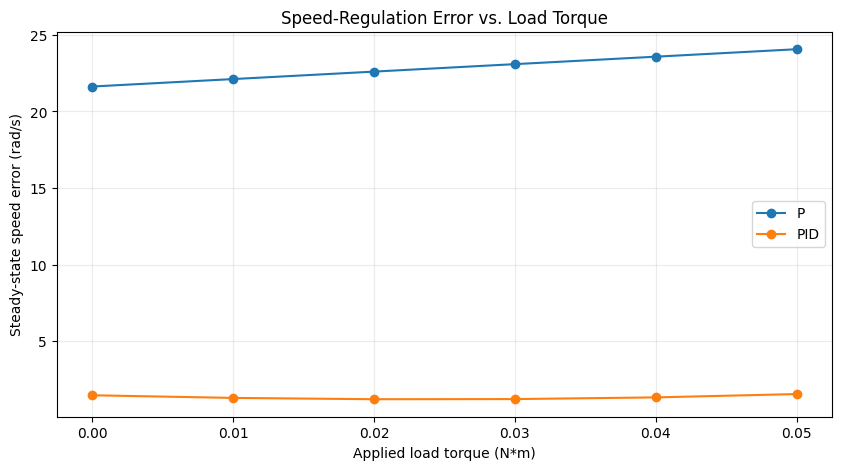

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

for controller_name in ["P", "PID"]:
    subset = load_df[load_df["Controller"] == controller_name]
    ax.plot(
        subset["Load torque (N*m)"],
        subset["Steady-state error (rad/s)"],
        marker="o",
        label=controller_name
    )

ax.set_xlabel("Applied load torque (N*m)")
ax.set_ylabel("Steady-state speed error (rad/s)")
ax.set_title("Speed-Regulation Error vs. Load Torque")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 5. Final engineering comparison

This section summarizes the main findings numerically.  
The conclusions should be based on these outputs rather than on assumptions about which controller is universally better.

In [ ]:
# Optimize metric extraction by referencing the pre-calculated baseline_metrics DataFrame
comparison = pd.DataFrame({
    "Metric": [
        "Rise time (s)",
        "Overshoot (%)",
        "RMSE (rad/s)",
        "Steady-state error (rad/s)",
        "IAE (rad/s*s)",
        "Control effort (V*s)",
        "Post-load mean speed (rad/s)"
    ],
    "P control": [
        baseline_metrics.loc["P control", "Rise time (s)"],
        baseline_metrics.loc["P control", "Overshoot (%)"],
        baseline_metrics.loc["P control", "RMSE (rad/s)"],
        baseline_metrics.loc["P control", "Steady-state error (rad/s)"],
        baseline_metrics.loc["P control", "IAE (rad/s*s)"],
        baseline_metrics.loc["P control", "Control effort (V*s)"],
        baseline_metrics.loc["P control", "Post-load mean speed (rad/s)"],
    ],
    "PID control": [
        baseline_metrics.loc["PID control", "Rise time (s)"],
        baseline_metrics.loc["PID control", "Overshoot (%)"],
        baseline_metrics.loc["PID control", "RMSE (rad/s)"],
        baseline_metrics.loc["PID control", "Steady-state error (rad/s)"],
        baseline_metrics.loc["PID control", "IAE (rad/s*s)"],
        baseline_metrics.loc["PID control", "Control effort (V*s)"],
        baseline_metrics.loc["PID control", "Post-load mean speed (rad/s)"],
    ]
})

display(comparison.round(4))

print("PROJECT CHECK")
print("-------------")
print("Model: OK")
print("Open-loop/P/PID comparison: OK")
print("Load-disturbance experiment: OK")
print("Measurement-noise Monte Carlo: OK")
print("Load-sweep experiment: OK")
print("Next step after successful execution: inspect the numerical results and lock the final research claims.")

,Metric,P control,PID control
0,Rise time (s),NaN,2.9870
1,Overshoot (%),0.0000,5.2403
2,RMSE (rad/s),32.7525,27.2030
3,Steady-state error (rad/s),23.0867,1.2225
4,IAE (rad/s*s),153.7422,96.2958
5,Control effort (V*s),37.2573,53.9027
6,Post-load mean speed (rad/s),36.9133,60.7817


PROJECT CHECK
-------------
Model: OK
Open-loop/P/PID comparison: OK
Load-disturbance experiment: OK
Measurement-noise Monte Carlo: OK
Load-sweep experiment: OK
Next step after successful execution: inspect the numerical results and lock the final research claims.


## 6. Export results

Run this final cell only after the notebook has executed successfully.  
It creates CSV files containing the main numerical results for later use in the paper.

In [ ]:
baseline_metrics.to_csv("dc_motor_baseline_metrics.csv")
noise_df.to_csv("dc_motor_noise_trials.csv", index=False)
load_df.to_csv("dc_motor_load_sweep.csv", index=False)

print("Saved:")
print("- dc_motor_baseline_metrics.csv")
print("- dc_motor_noise_trials.csv")
print("- dc_motor_load_sweep.csv")

Saved:
- dc_motor_baseline_metrics.csv
- dc_motor_noise_trials.csv
- dc_motor_load_sweep.csv
